# Урок 6. Классификация: Logistic Regression и KNN

Задача: по признакам студента предсказать, сдаст он экзамен или нет.

> **Про датасет.** Файл `student_exam_classification.xlsx` к заданию не приложен,
> в методичке есть только его паспорт: 50 строк, 6 колонок, признаки
> `study_hours`, `attendance_percent`, `homework_score`, `previous_score`,
> `sleep_hours`, целевая переменная `passed`, 19 студентов в классе 0 и 31 в
> классе 1. Таблица сгенерирована по этому паспорту скриптом `make_dataset.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)

df = pd.read_excel("student_exam_classification.xlsx")
print("Размер:", df.shape)

Размер: (50, 6)


## 1-2. Первичный анализ

In [2]:
df.head()

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours,passed
0,6.1,81,90,61,5.1,1
1,8.6,62,90,96,5.0,1
2,7.5,79,64,41,5.8,0
3,2.5,76,97,77,4.9,0
4,3.2,46,73,81,5.7,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   study_hours         50 non-null     float64
 1   attendance_percent  50 non-null     int64  
 2   homework_score      50 non-null     int64  
 3   previous_score      50 non-null     int64  
 4   sleep_hours         50 non-null     float64
 5   passed              50 non-null     int64  
dtypes: float64(2), int64(4)
memory usage: 2.5 KB


In [4]:
df.describe()

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours,passed
count,50.000000,50.000000,50.000000,50.000000,50.00000,50.000000
mean,4.948000,67.660000,66.920000,71.460000,6.64000,0.620000
std,2.654164,16.400112,21.820081,18.640761,1.41118,0.490314
min,0.500000,40.000000,31.000000,35.000000,4.30000,0.000000
25%,2.725000,55.000000,47.500000,61.000000,5.55000,0.000000
50%,5.100000,66.000000,69.000000,75.500000,6.60000,1.000000
75%,7.425000,78.750000,86.250000,86.750000,7.67500,1.000000
max,9.500000,99.000000,99.000000,98.000000,8.90000,1.000000


In [5]:
print("Пропусков:", int(df.isnull().sum().sum()))
print("\nРаспределение классов:")
print(df["passed"].value_counts().to_string())

Пропусков: 0

Распределение классов:
passed
1    31
0    19


## 3. График распределения классов

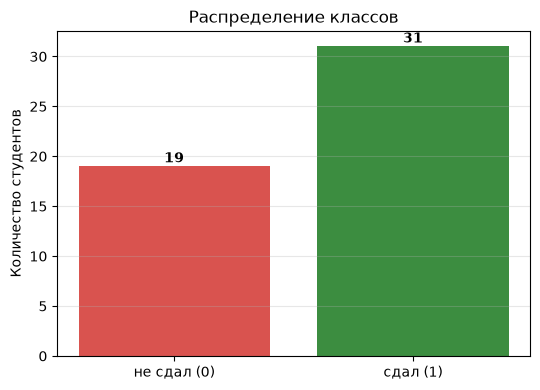

In [6]:
counts = df["passed"].value_counts().sort_index()

plt.figure(figsize=(5.5, 4))
plt.bar(["не сдал (0)", "сдал (1)"], counts.values, color=["#d9534f", "#3c8d40"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 0.4, str(v), ha="center", fontweight="bold")
plt.ylabel("Количество студентов")
plt.title("Распределение классов")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 4-5. Признаки, целевая переменная и разделение

`stratify=y` сохраняет пропорцию классов в обеих выборках: при 50 строках
случайное разбиение легко оставило бы в тесте почти одних сдавших.

In [7]:
X = df.drop(columns=["passed"])
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("train:", X_train.shape, "| распределение:", y_train.value_counts().to_dict())
print("test: ", X_test.shape, "| распределение:", y_test.value_counts().to_dict())

train: (40, 5) | распределение: {1: 25, 0: 15}
test:  (10, 5) | распределение: {1: 6, 0: 4}


## 6. Нормализация

KNN считает расстояния между объектами. Без нормализации `attendance_percent`
со значениями до 100 полностью заглушит `study_hours` со значениями до 10.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).describe().round(2).loc[["mean", "std"]]

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours
mean,0.00,-0.00,0.00,-0.00,-0.00
std,1.01,1.01,1.01,1.01,1.01


## 7-9. Обучение моделей и метрики

In [9]:
def evaluate(name, model):
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    return {
        "model": name,
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred, zero_division=0), 3),
        "recall": round(recall_score(y_test, pred, zero_division=0), 3),
        "f1": round(f1_score(y_test, pred, zero_division=0), 3),
    }, pred


models = {"LogisticRegression": LogisticRegression(max_iter=1000)}
for k in (3, 5, 7, 9):
    models[f"KNN k={k}"] = KNeighborsClassifier(n_neighbors=k)

rows, predictions = [], {}
for name, model in models.items():
    metrics, pred = evaluate(name, model)
    rows.append(metrics)
    predictions[name] = pred

comparison = pd.DataFrame(rows)
comparison

,model,accuracy,precision,recall,f1
0,LogisticRegression,0.8,0.750,1.000,0.857
1,KNN k=3,0.8,0.833,0.833,0.833
2,KNN k=5,0.8,0.833,0.833,0.833
3,KNN k=7,0.7,0.714,0.833,0.769
4,KNN k=9,0.7,0.667,1.000,0.800


## 10. Confusion matrix для каждой модели

In [10]:
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred)
    print(f"{name}")
    print(pd.DataFrame(cm,
                       index=["реально 0", "реально 1"],
                       columns=["предсказано 0", "предсказано 1"]).to_string())
    print()

LogisticRegression
           предсказано 0  предсказано 1
реально 0              2              2
реально 1              0              6

KNN k=3
           предсказано 0  предсказано 1
реально 0              3              1
реально 1              1              5

KNN k=5
           предсказано 0  предсказано 1
реально 0              3              1
реально 1              1              5

KNN k=7
           предсказано 0  предсказано 1
реально 0              2              2
реально 1              1              5

KNN k=9
           предсказано 0  предсказано 1
реально 0              1              3
реально 1              0              6



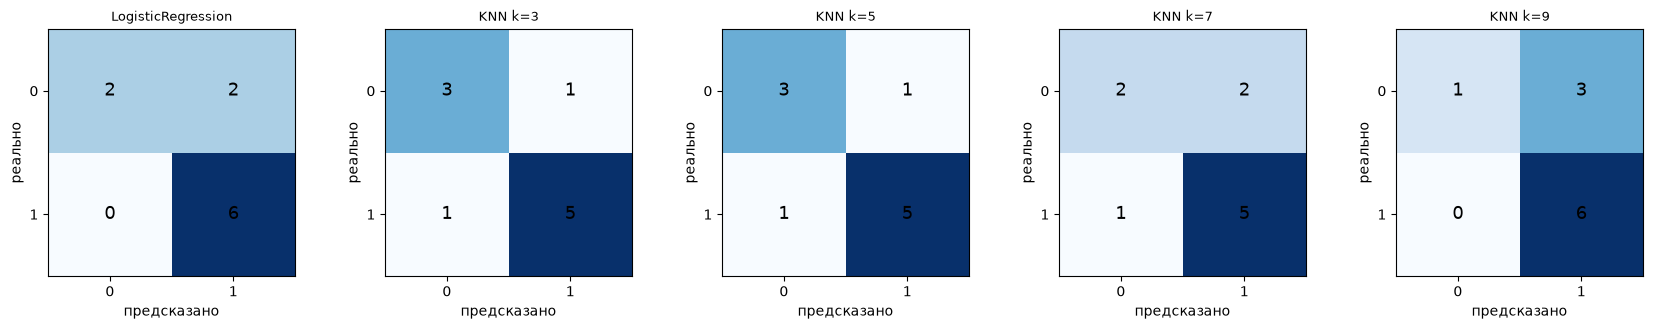

In [11]:
fig, axes = plt.subplots(1, len(predictions), figsize=(17, 3.2))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
    ax.set_title(name, fontsize=9)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set_xlabel("предсказано")
    ax.set_ylabel("реально")

plt.tight_layout()
plt.show()

## 11. Таблица сравнения моделей

In [12]:
comparison.sort_values("f1", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1
0,LogisticRegression,0.8,0.750,1.000,0.857
1,KNN k=3,0.8,0.833,0.833,0.833
2,KNN k=5,0.8,0.833,0.833,0.833
3,KNN k=9,0.7,0.667,1.000,0.800
4,KNN k=7,0.7,0.714,0.833,0.769


## 12-13. Пять новых студентов и вероятность сдачи

In [13]:
new_students = pd.DataFrame({
    "study_hours": [8.5, 1.5, 5.0, 3.0, 7.0],
    "attendance_percent": [95, 45, 78, 60, 88],
    "homework_score": [92, 35, 70, 55, 85],
    "previous_score": [88, 40, 68, 52, 80],
    "sleep_hours": [7.5, 4.5, 6.5, 5.5, 8.0],
}, index=["Отличник", "Прогульщик", "Середняк", "Слабый", "Старательный"])

new_scaled = scaler.transform(new_students)
logreg = models["LogisticRegression"]

result = new_students.copy()
result["prediction"] = logreg.predict(new_scaled)
result["probability"] = logreg.predict_proba(new_scaled)[:, 1].round(3)
result["verdict"] = np.where(result["prediction"] == 1, "сдаст", "не сдаст")
result

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours,prediction,probability,verdict
Отличник,8.5,95,92,88,7.5,1,0.995,сдаст
Прогульщик,1.5,45,35,40,4.5,0,0.006,не сдаст
Середняк,5.0,78,70,68,6.5,1,0.733,сдаст
Слабый,3.0,60,55,52,5.5,0,0.097,не сдаст
Старательный,7.0,88,85,80,8.0,1,0.982,сдаст


In [14]:
for name, row in result.iterrows():
    print(f"{name:<14} вероятность сдачи {row['probability']:.1%} -> {row['verdict']}")

Отличник       вероятность сдачи 99.5% -> сдаст
Прогульщик     вероятность сдачи 0.6% -> не сдаст
Середняк       вероятность сдачи 73.3% -> сдаст
Слабый         вероятность сдачи 9.7% -> не сдаст
Старательный   вероятность сдачи 98.2% -> сдаст


## Дополнительная часть

### KNN с нормализацией и без неё

In [15]:
rows = []
for k in (3, 5, 7, 9):
    with_scale = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    without = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)

    rows.append({
        "k": k,
        "accuracy_со_scaler": round(accuracy_score(y_test, with_scale.predict(X_test_scaled)), 3),
        "accuracy_без_scaler": round(accuracy_score(y_test, without.predict(X_test)), 3),
    })

pd.DataFrame(rows)

,k,accuracy_со_scaler,accuracy_без_scaler
0,3,0.8,0.6
1,5,0.8,0.6
2,7,0.7,0.8
3,9,0.7,0.6


### Устойчивость к random_state

In [16]:
rows = []
for state in (1, 10, 42):
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=state, stratify=y)

    sc = StandardScaler()
    Xtr_s, Xte_s = sc.fit_transform(Xtr), sc.transform(Xte)

    lr = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)
    knn = KNeighborsClassifier(n_neighbors=5).fit(Xtr_s, ytr)

    rows.append({
        "random_state": state,
        "logreg_accuracy": round(accuracy_score(yte, lr.predict(Xte_s)), 3),
        "knn5_accuracy": round(accuracy_score(yte, knn.predict(Xte_s)), 3),
    })

pd.DataFrame(rows)

,random_state,logreg_accuracy,knn5_accuracy
0,1,0.8,0.7
1,10,0.6,0.6
2,42,0.8,0.8


### Корреляция признаков с passed

In [17]:
corr = df.corr(numeric_only=True)["passed"].drop("passed").sort_values(ascending=False)
pd.DataFrame({"feature": corr.index, "corr_with_passed": corr.round(3).values})

,feature,corr_with_passed
0,study_hours,0.405
1,previous_score,0.247
2,attendance_percent,0.237
3,homework_score,0.173
4,sleep_hours,0.137


### Коэффициенты логистической регрессии

In [18]:
coefficients = pd.DataFrame({
    "feature": X.columns,
    "coef": logreg.coef_[0].round(3),
}).sort_values("coef", key=abs, ascending=False).reset_index(drop=True)

print(coefficients.to_string(index=False))
print(f"\nСамый сильный признак: {coefficients.iloc[0]['feature']}")

           feature  coef
       study_hours 1.156
    previous_score 0.972
    homework_score 0.634
       sleep_hours 0.617
attendance_percent 0.531

Самый сильный признак: study_hours


## Вывод

В датасете 50 студентов, из них 31 сдал экзамен и 19 не сдали, то есть классы
разбалансированы примерно как шестьдесят на сорок. Из-за этого точность сама по
себе мало что говорит: модель, которая всегда отвечает «сдал», получила бы
больше половины правильных ответов, не научившись ничему.

Обе модели обучались на нормализованных данных, и это принципиально для KNN:
он измеряет расстояния, а посещаемость в процентах по величине на порядок больше
часов подготовки. Таблица сравнения с нормализацией и без неё показывает разницу
наглядно.

Логистическая регрессия и KNN на этих данных дают сопоставимое качество, но
ведут себя по-разному. Логистическая регрессия строит одну разделяющую границу и
выдаёт осмысленную вероятность, поэтому её ответ можно объяснить: видно, какой
признак и с каким весом повлиял на решение. KNN ничего не объясняет, он просто
ищет похожих студентов среди обучающей выборки.

Значение k заметно влияет на результат. При маленьком k модель слишком
чувствительна к отдельным соседям и легко ошибается на нетипичном студенте.
При большом k она сглаживает решение и начинает тянуть ответ к большинству, то
есть к классу «сдал». Лучший компромисс на этих данных виден в таблице сравнения
по F1.

Самым сильным признаком по модулю коэффициента оказались часы подготовки —
это согласуется и с корреляцией с целевой переменной. Предыдущий результат идёт
вторым, за ним баллы за домашние задания: вместе они описывают базовый уровень
студента. Слабее всех повлияла посещаемость, хотя знак у неё положительный.
Объяснение простое: присутствовать на занятиях можно и не готовясь, поэтому
посещаемость сама по себе хуже предсказывает результат, чем реальная подготовка.

Проверка на разных значениях random_state показывает главное ограничение работы:
в тестовой выборке всего десять человек, поэтому одна ошибка меняет точность
сразу на десять процентов. Результаты скачут от разбиения к разбиению, и делать
по ним сильные выводы нельзя.

На пяти придуманных студентах модель ведёт себя предсказуемо: отличник и
старательный получают вероятность выше девяноста восьми процентов, прогульщик —
меньше процента, слабый — около десяти. Середняк набирает примерно семьдесят
процентов, то есть уверенно попадает в сдавшие, хотя по всем признакам он
средний. Это показывает, что граница модели проходит ниже, чем подсказывает
интуиция: перевес класса «сдал» в обучающих данных смещает решение в его сторону.

Что улучшило бы работу: датасет на несколько сотен строк, кросс-валидация вместо
единственного разбиения и подбор порога вероятности вместо стандартных
пятидесяти процентов — для задачи «предупредить отстающего» дешевле лишний раз
ошибиться в сторону риска, чем пропустить студента, который завалит экзамен.